<a href="https://colab.research.google.com/github/laboratoriodecodigos/Colab-Python/blob/main/YOLO_World_Educativo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# YOLO-World: detección de objetos con vocabulario abierto
### Imágenes y video · Ejemplos educativos · Conteo de visitantes

**¿Qué vas a aprender?**
1. Qué es la detección de **vocabulario abierto** (*open-vocabulary*) y por qué YOLO-World es distinto a un YOLO tradicional.
2. Cómo detectar objetos **solo escribiendo su nombre**, sin reentrenar.
3. Cómo influyen los hiperparámetros: **umbral de confianza**, **NMS** y la **redacción de los prompts**.
4. Cómo procesar **video**: seguimiento de objetos (*tracking*), conteo con **línea virtual**, **mapa de calor** y análisis temporal.
5. Cómo exportar resultados (CSV/JSON) y analizarlos con **pandas**.

> **Requisito:** en Colab, activa la GPU en *Entorno de ejecución → Cambiar tipo de entorno → T4 GPU*.

---

## Idea clave: ¿qué hace diferente a YOLO-World?

| | YOLO tradicional (p. ej. YOLOv8 en COCO) | YOLO-World |
|---|---|---|
| Clases | Fijas (80 en COCO) | **Cualquier texto** que escribas |
| Agregar una clase nueva | Etiquetar datos + reentrenar | Escribir la palabra: `"casco"`, `"mochila roja"` |
| Cómo "entiende" la clase | Un índice numérico | Un **embedding de texto** (codificador CLIP) |

**Arquitectura simplificada:**

```
 "person", "hat", "backpack"  ──►  Codificador de texto (CLIP)  ──►  embeddings de texto ─┐
                                                                                          ▼
 imagen ──► Backbone YOLO ──► características visuales ──► RepVL-PAN (fusión visión-lenguaje) ──► cajas + similitud texto-región
```

El paradigma es **"prompt-then-detect"**: el vocabulario se codifica **una sola vez** con `set_classes()` y después cada inferencia es tan rápida como un YOLO normal. Por eso agregar más clases casi no afecta la velocidad (lo comprobaremos al final).

**Consecuencia práctica:** las confianzas de YOLO-World son *similitudes* entre región y texto, no probabilidades calibradas. Para objetos poco comunes los valores pueden ser muy bajos (0.01–0.1), por eso hay que **experimentar con el umbral**.

## 0. Preparación del entorno

In [1]:
# Verificamos que haya GPU disponible
!nvidia-smi

Wed Nov 18 17:55:07 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   60C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# Instalación de dependencias (tarda ~1-2 min la primera vez)
#  - supervision: anotación, sinks CSV/JSON, utilidades de video
#  - trackers:    algoritmos de seguimiento (ByteTrack). En supervision 0.31+ ya no viene incluido
#  - inference:   motor de Roboflow que incluye YOLO-World
!pip install -q -U supervision trackers
!pip install -q "inference-gpu[yolo-world]" dill

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing

In [3]:
import os, time, base64, subprocess, warnings
from collections import Counter

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import supervision as sv
from tqdm.auto import tqdm
from IPython.display import HTML, display
from trackers import ByteTrackTracker

warnings.filterwarnings("ignore")  # oculta avisos de dependencias que no afectan al ejemplo

from inference.models.yolo_world.yolo_world import YOLOWorld

print("supervision:", sv.__version__)

/usr/local/lib/python3.13/dist-packages/deprecate/deprecation.py:319: FutureWarning: target=None is deprecated since `v0.8`; use `TargetMode.NOTIFY` instead. Will be removed in `v1.0`.
  return _callable_pack(source, _stacklevel + 1, _is_static)  # type: ignore[call-arg, arg-type]


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/tmp/roboflow-inference/ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
supervision: 0.30.9


### Datos de ejemplo
Usamos `wget -nc` para **no descargar duplicados** (en el notebook original se generaban `test.jpeg.1`, `test.jpeg.2`, …).

In [4]:
DATA_DIR = "/content/datos"
OUT_DIR  = "/content/resultados"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

!wget -nc -q -P {DATA_DIR} https://storage.googleapis.com/adonaivera_certified/test.jpeg
!wget -nc -q -P {DATA_DIR} https://storage.googleapis.com/adonaivera_certified/test_demo1.mp4

SOURCE_IMAGE_PATH = f"{DATA_DIR}/test.jpeg"
SOURCE_VIDEO_PATH = f"{DATA_DIR}/test_demo1.mp4"
print(os.listdir(DATA_DIR))

['test.jpeg', 'test_demo1.mp4']


#### (Opcional) Sube tus propias imágenes o videos
Ejecuta la siguiente celda y elige archivos desde tu computadora. Se guardan en `/content/datos/`.

In [ ]:
SUBIR_ARCHIVOS = False   # ← cambia a True para subir archivos

if SUBIR_ARCHIVOS:
    from google.colab import files
    subidos = files.upload()
    for nombre, contenido in subidos.items():
        with open(f"{DATA_DIR}/{nombre}", "wb") as f:
            f.write(contenido)
        print("Guardado:", f"{DATA_DIR}/{nombre}")

## 1. Cargar el modelo (una sola vez)

YOLO-World viene en varios tamaños. A mayor tamaño, más precisión y menos velocidad:

| `model_id` | Tamaño | Uso típico |
|---|---|---|
| `yolo_world/s` | pequeño | tiempo real en hardware modesto |
| `yolo_world/m` | mediano | equilibrio |
| `yolo_world/l` | grande | **el que usamos aquí** |
| `yolo_world/x` | extra grande | máxima precisión |

En el notebook original el modelo se cargaba **dos veces** (~20 s cada una). No es necesario: basta con llamar a `set_classes()` para cambiar el vocabulario.

In [5]:
t0 = time.time()
model = YOLOWorld(model_id="yolo_world/l")
print(f"Modelo cargado en {time.time() - t0:.1f} s")

Creating inference sessions
CLIP model loaded in 10.63 seconds
Modelo cargado en 12.6 s


## 2. Funciones auxiliares

En lugar de repetir el mismo bloque de código en cada celda, lo encapsulamos en funciones. Así cada ejemplo se concentra en **la idea que queremos mostrar**.

| Función | Qué hace |
|---|---|
| `detectar()` | Define vocabulario → infiere → aplica NMS → filtra cajas gigantes |
| `anotar()` | Dibuja cajas y etiquetas `clase confianza` con tamaño de texto adaptado a la resolución |
| `resumen()` | Tabla de conteo y confianza por clase |
| `mostrar_video()` | Reproduce un MP4 dentro del notebook |

In [6]:
_clases_actuales = None

def detectar(imagen, clases, confianza=0.05, nms=0.5, nms_agnostico=False, area_max=0.8):
    """
    Ejecuta YOLO-World sobre una imagen BGR.

    clases         : lista de textos (el "vocabulario")
    confianza      : umbral mínimo de confianza
    nms            : umbral IoU para Non-Max Suppression (None = sin NMS)
    nms_agnostico  : True = suprime cajas solapadas aunque sean de clases distintas
    area_max       : descarta cajas que ocupen más de esta fracción de la imagen
                     (YOLO-World a veces propone una caja que cubre toda la escena)
    """
    global _clases_actuales
    if clases != _clases_actuales:          # set_classes codifica el texto con CLIP:
        model.set_classes(clases)           # solo lo repetimos si el vocabulario cambió
        _clases_actuales = list(clases)

    resultados = model.infer(imagen, confidence=confianza)
    det = sv.Detections.from_inference(resultados)

    if nms is not None and len(det) > 0:
        det = det.with_nms(threshold=nms, class_agnostic=nms_agnostico)

    if area_max is not None and len(det) > 0:
        h, w = imagen.shape[:2]
        det = det[(det.area / (h * w)) < area_max]
    return det


def anotar(imagen, det, mostrar_confianza=True):
    """Dibuja cajas y etiquetas; grosor y texto se adaptan a la resolución."""
    wh = (imagen.shape[1], imagen.shape[0])
    grosor = sv.calculate_optimal_line_thickness(resolution_wh=wh)
    escala = sv.calculate_optimal_text_scale(resolution_wh=wh)

    box = sv.BoxAnnotator(thickness=grosor)
    lab = sv.LabelAnnotator(text_scale=escala, text_thickness=grosor,
                            text_color=sv.Color.BLACK, smart_position=True)
    nombres = det.data.get("class_name", [str(c) for c in det.class_id])
    if mostrar_confianza:
        etiquetas = [f"{n} {c:.2f}" for n, c in zip(nombres, det.confidence)]
    else:
        etiquetas = list(nombres)

    out = box.annotate(imagen.copy(), det)
    return lab.annotate(out, det, labels=etiquetas)


def resumen(det):
    """DataFrame con número de detecciones y confianza por clase."""
    if len(det) == 0:
        return pd.DataFrame(columns=["clase", "n", "conf_media", "conf_max"])
    df = pd.DataFrame({"clase": det.data["class_name"], "conf": det.confidence})
    return (df.groupby("clase")["conf"]
              .agg(n="count", conf_media="mean", conf_max="max")
              .round(3).sort_values("n", ascending=False).reset_index())


def mostrar_video(ruta, ancho=640):
    """
    OpenCV guarda MP4 con códec 'mp4v', que los navegadores no reproducen.
    Lo convertimos a H.264 con ffmpeg y lo incrustamos en el notebook.
    """
    web = ruta.replace(".mp4", "_web.mp4")
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", ruta,
                    "-vcodec", "libx264", "-preset", "veryfast", "-crf", "28",
                    "-pix_fmt", "yuv420p", web], check=True)
    datos = base64.b64encode(open(web, "rb").read()).decode()
    display(HTML(f'<video width="{ancho}" controls><source src="data:video/mp4;base64,{datos}" type="video/mp4"></video>'))

# Parte I · Imágenes

## Ejemplo 1 · Detección básica con una sola clase

Empezamos con lo más simple: el vocabulario es solo `["person"]`.
Observa que **no hay entrenamiento**: el modelo nunca vio "esta" clase como índice fijo, solo compara regiones de la imagen con el texto.

Resolución: 2688 x 1512
Personas detectadas: 81


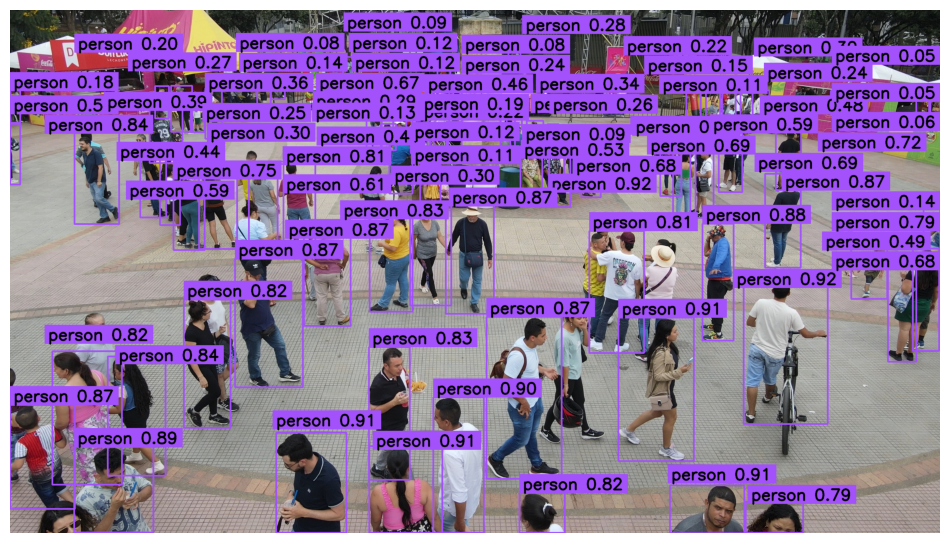

In [7]:
image = cv2.imread(SOURCE_IMAGE_PATH)
print("Resolución:", image.shape[1], "x", image.shape[0])

det = detectar(image, ["person"], confianza=0.05)
print(f"Personas detectadas: {len(det)}")
sv.plot_image(anotar(image, det), (12, 12))

## Ejemplo 2 · Vocabulario abierto: varias clases sin reentrenar

Ahora escribimos varias clases. Cada texto se convierte en un embedding y el modelo busca regiones parecidas a **cada uno**.

> 💬 **Pregunta para el grupo:** ¿qué clases de este vocabulario existen en COCO y cuáles no? (`hat` y `sunglasses` **no** están en COCO; un YOLOv8 estándar no podría detectarlas).

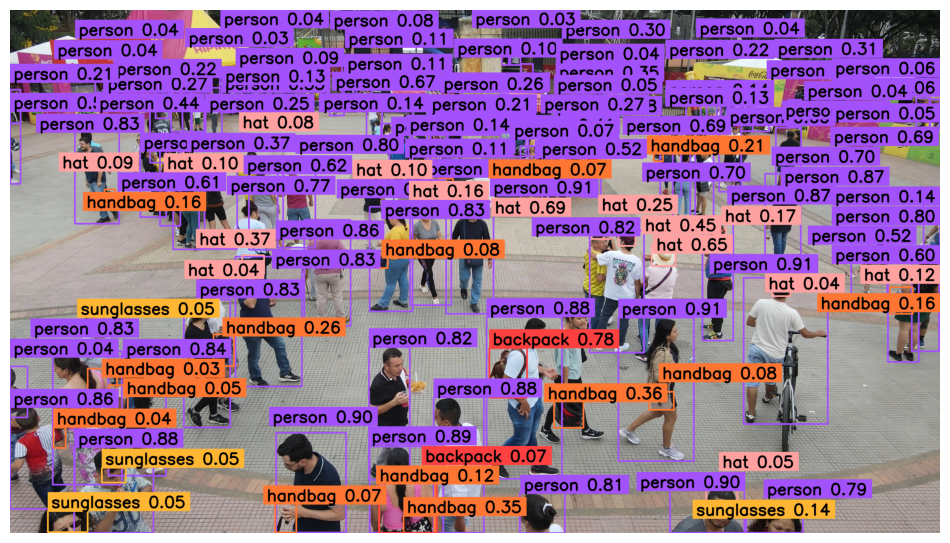

,clase,n,conf_media,conf_max
0,person,91,0.458,0.914
1,hat,15,0.224,0.690
2,handbag,14,0.145,0.361
3,sunglasses,4,0.073,0.136
4,backpack,2,0.428,0.784


In [8]:
VOCABULARIO = ["person", "backpack", "hat", "handbag", "sunglasses"]

det = detectar(image, VOCABULARIO, confianza=0.03)
sv.plot_image(anotar(image, det), (12, 12))
resumen(det)

## Ejemplo 3 · ¿Cómo afecta el umbral de confianza?

El umbral decide **qué detecciones conservamos**. Es el clásico compromiso:

- Umbral **bajo** → detecta más objetos (↑ *recall*) pero aparecen **falsos positivos**.
- Umbral **alto** → menos errores (↑ *precisión*) pero se **pierden objetos**.

El notebook original usaba `0.003`, un valor muy bajo. Veamos qué pasa con distintos valores:

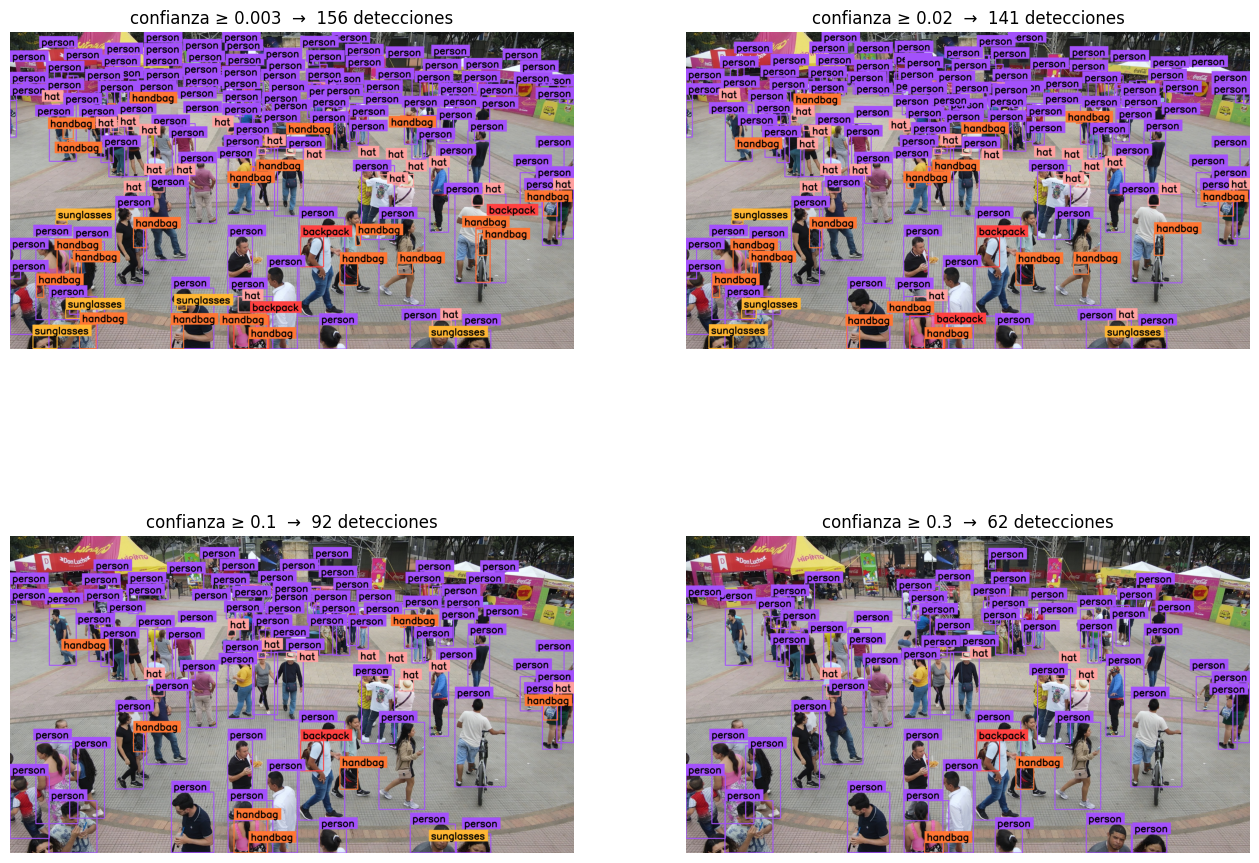

In [9]:
umbrales = [0.003, 0.02, 0.1, 0.3]
imgs, titulos = [], []
for u in umbrales:
    d = detectar(image, VOCABULARIO, confianza=u)
    imgs.append(anotar(image, d, mostrar_confianza=False))
    titulos.append(f"confianza ≥ {u}  →  {len(d)} detecciones")

sv.plot_images_grid(imgs, grid_size=(2, 2), titles=titulos, size=(16, 12))

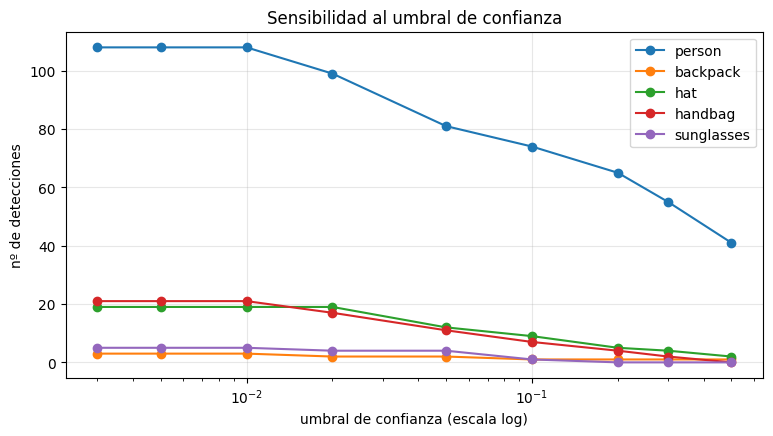

,person,backpack,hat,handbag,sunglasses
umbral,,,,,
0.003,108,3,19,21,5
0.005,108,3,19,21,5
0.010,108,3,19,21,5
0.020,99,2,19,17,4
0.050,81,2,12,11,4
0.100,74,1,9,7,1
0.200,65,1,5,4,0
0.300,55,1,4,2,0
0.500,41,1,2,0,0


In [10]:
# Misma idea en forma de curva: nº de detecciones por clase vs umbral
umbrales = [0.003, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5]
filas = []
for u in umbrales:
    d = detectar(image, VOCABULARIO, confianza=u)
    conteo = Counter(d.data["class_name"]) if len(d) else Counter()
    filas.append({"umbral": u, **{c: conteo.get(c, 0) for c in VOCABULARIO}})

df_umbral = pd.DataFrame(filas).set_index("umbral")
ax = df_umbral.plot(marker="o", logx=True, figsize=(9, 4.5))
ax.set_xlabel("umbral de confianza (escala log)"); ax.set_ylabel("nº de detecciones")
ax.set_title("Sensibilidad al umbral de confianza"); ax.grid(alpha=.3)
plt.show()
df_umbral

**Observa:** las clases frecuentes (`person`) mantienen confianzas altas, mientras que las raras (`sunglasses`, `hat`) desaparecen rápido al subir el umbral. Por eso en YOLO-World conviene **ajustar el umbral según la clase** o elegir uno bajo y filtrar después.

## Ejemplo 4 · Ingeniería de *prompts*: la redacción importa

Como las clases son texto, **cómo las escribas cambia el resultado**. Comparamos cuatro formas de buscar "algo en la cabeza":

| Prompt | Qué esperamos |
|---|---|
| `hat` | sombreros en general |
| `cap` | gorras |
| `person with hat` | ¿la persona completa o solo el sombrero? |
| `red backpack` | ¿entiende atributos como el color? |

> En el notebook original se usaba `"persons with backpack"`. Este tipo de frase suele producir cajas sobre **la persona entera**, no sobre la mochila: el modelo localiza el sustantivo principal.

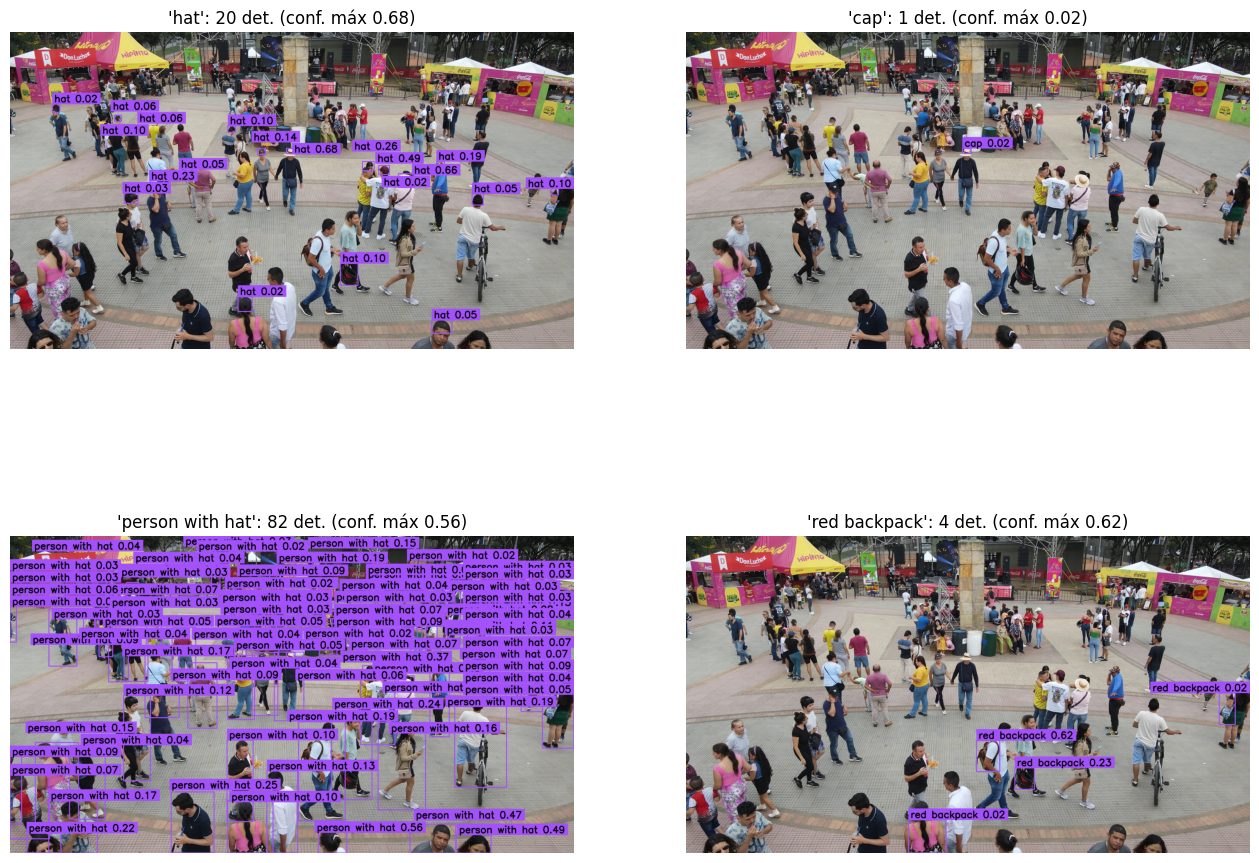

In [11]:
prompts = [["hat"], ["cap"], ["person with hat"], ["red backpack"]]
imgs, titulos = [], []
for p in prompts:
    d = detectar(image, p, confianza=0.02)
    imgs.append(anotar(image, d))
    conf = f"{d.confidence.max():.2f}" if len(d) else "-"
    titulos.append(f"{p[0]!r}: {len(d)} det. (conf. máx {conf})")

sv.plot_images_grid(imgs, grid_size=(2, 2), titles=titulos, size=(16, 12))

**Buenas prácticas de prompts:**
- Usa **sustantivos concretos en inglés** (el codificador CLIP se entrenó mayoritariamente en inglés).
- Si dos clases se pisan (p. ej. `hat` y `cap`), usa **NMS agnóstico** (siguiente ejemplo) o quédate con una.
- Los **atributos** (color, material) a veces funcionan, pero verifica siempre visualmente.
- Agregar una clase "distractora" (p. ej. `"background"` o `"wall"`) puede reducir falsos positivos.

## Ejemplo 5 · Non-Max Suppression (NMS)

El detector propone muchas cajas solapadas para el mismo objeto. **NMS** se queda con la de mayor confianza y elimina las que se solapan más que un umbral de IoU (*Intersection over Union*).

- `threshold` **bajo** (p. ej. 0.1 como en el original) → elimina cajas aunque se solapen poco: en multitudes **puede borrar personas reales** que están juntas.
- `class_agnostic=True` → también elimina cajas solapadas de **clases distintas** (útil cuando `hat` y `cap` marcan el mismo objeto).

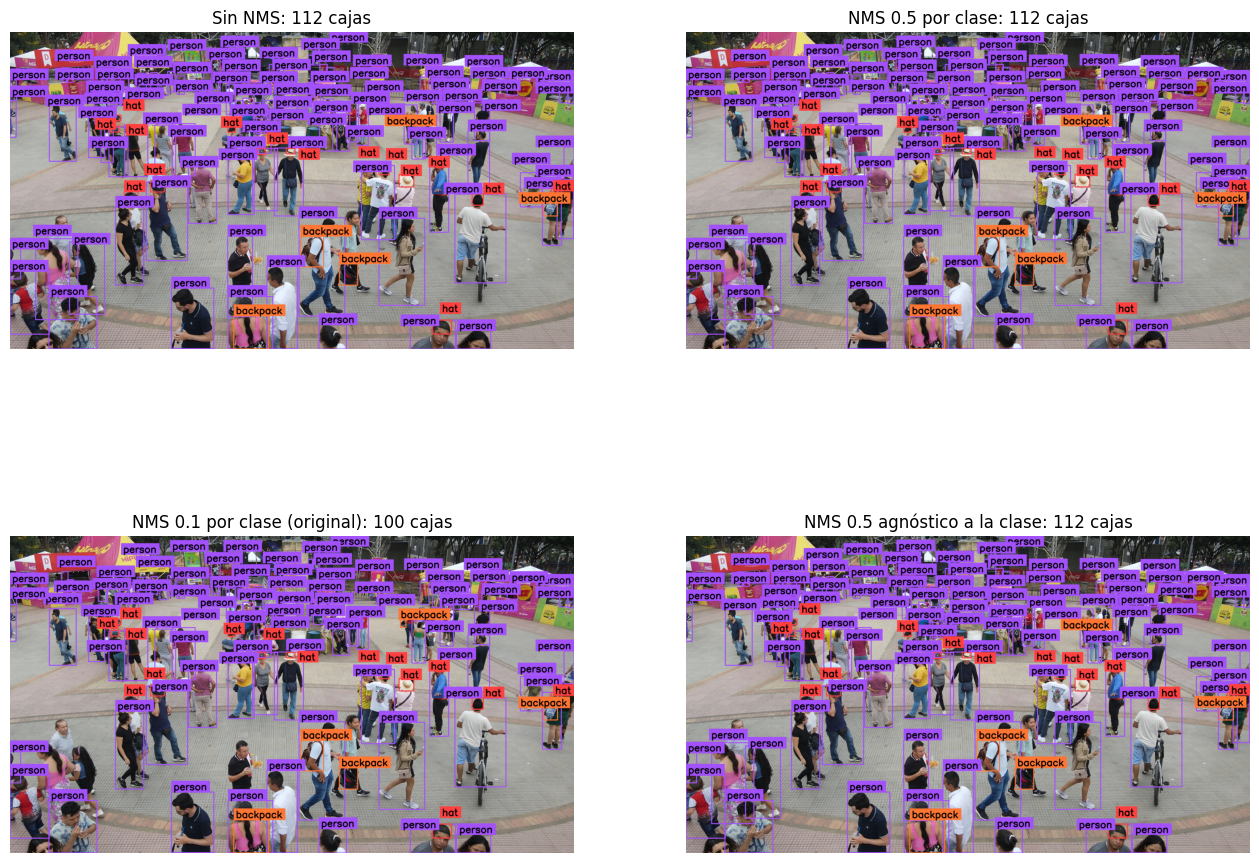

In [12]:
voc = ["person", "hat", "cap", "backpack"]
configs = [
    ("Sin NMS",                        dict(nms=None)),
    ("NMS 0.5 por clase",              dict(nms=0.5)),
    ("NMS 0.1 por clase (original)",   dict(nms=0.1)),
    ("NMS 0.5 agnóstico a la clase",   dict(nms=0.5, nms_agnostico=True)),
]
imgs, titulos = [], []
for nombre, kw in configs:
    d = detectar(image, voc, confianza=0.03, **kw)
    imgs.append(anotar(image, d, mostrar_confianza=False))
    titulos.append(f"{nombre}: {len(d)} cajas")

sv.plot_images_grid(imgs, grid_size=(2, 2), titles=titulos, size=(16, 12))

## Ejemplo 6 · Guardar y analizar las detecciones

Exportamos a **CSV** y **JSON** con `supervision` (incluyendo un campo personalizado `campaña`) y analizamos con pandas.

> 🐞 En el original, el `CSVSink` se abría en una celda y se cerraba en otra, y el CSV del video **sobrescribía** el de la imagen. Aquí usamos `with` (se cierra solo) y nombres de archivo distintos.

In [13]:
VOCABULARIO = ["person", "backpack", "hat", "handbag"]
det = detectar(image, VOCABULARIO, confianza=0.03)

csv_img  = f"{OUT_DIR}/detecciones_imagen.csv"
json_img = f"{OUT_DIR}/detecciones_imagen.json"
with sv.CSVSink(csv_img) as csv_sink, sv.JSONSink(json_img) as json_sink:
    extra = {"campaña": "sombreros y mochilas", "archivo": os.path.basename(SOURCE_IMAGE_PATH)}
    csv_sink.append(det, custom_data=extra)
    json_sink.append(det, custom_data=extra)

df = pd.read_csv(csv_img)
df["ancho"] = df.x_max - df.x_min
df["alto"]  = df.y_max - df.y_min
df.head(10)

,x_min,y_min,x_max,y_max,class_id,confidence,tracker_id,archivo,campaña,class_name,ancho,alto
0,2120.952148,775.402374,2363.066895,1197.967010,0,0.914606,NaN,test.jpeg,sombreros y mochilas,person,242.114746,422.564636
1,1758.331543,890.850739,1976.780029,1304.713470,0,0.910283,NaN,test.jpeg,sombreros y mochilas,person,218.448486,413.862732
2,1260.178894,556.886780,1397.997375,879.430725,0,0.907208,NaN,test.jpeg,sombreros y mochilas,person,137.818481,322.543945
3,1908.885010,1374.318115,2123.614990,1512.000000,0,0.905577,NaN,test.jpeg,sombreros y mochilas,person,214.729980,137.681885
4,769.813049,1222.647827,971.319763,1510.706665,0,0.895573,NaN,test.jpeg,sombreros y mochilas,person,201.506714,288.058838
5,1039.270081,1262.270813,1252.584412,1511.443054,0,0.887034,NaN,test.jpeg,sombreros y mochilas,person,213.314331,249.172241
6,1223.970520,1120.261353,1369.399597,1511.683960,0,0.880326,NaN,test.jpeg,sombreros y mochilas,person,145.429077,391.422607
7,1377.787109,888.148315,1595.018066,1355.458862,0,0.876828,NaN,test.jpeg,sombreros y mochilas,person,217.230957,467.310547
8,185.216576,1262.979797,414.111549,1511.100769,0,0.876115,NaN,test.jpeg,sombreros y mochilas,person,228.894974,248.120972
9,1156.403442,559.443848,1275.568237,854.756348,0,0.872184,NaN,test.jpeg,sombreros y mochilas,person,119.164795,295.312500


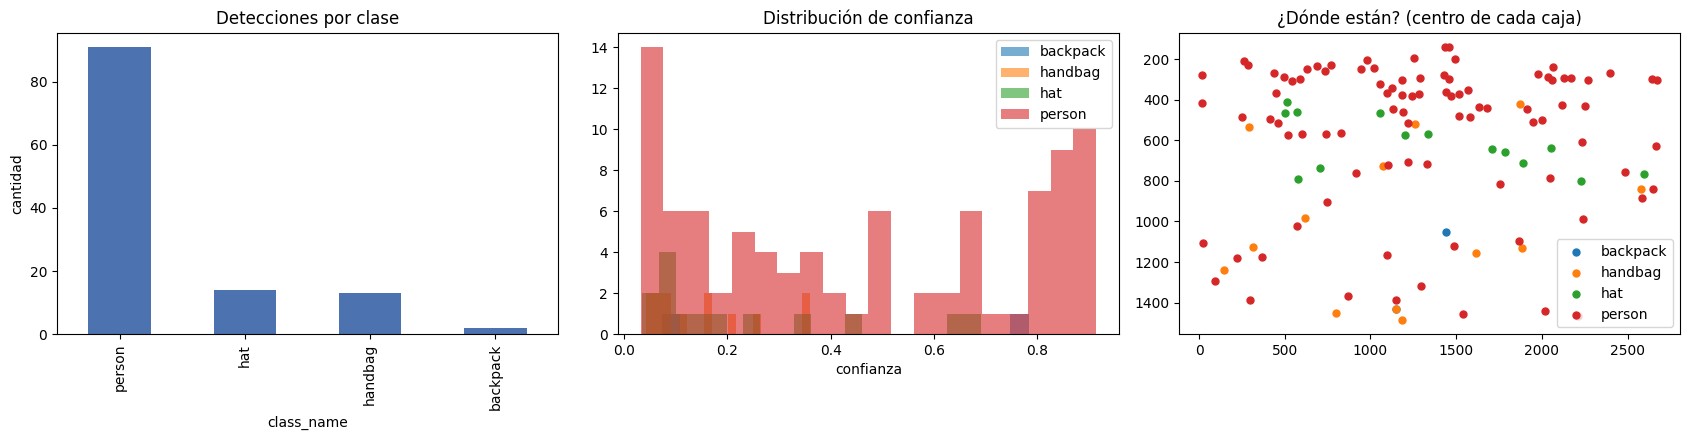

In [14]:
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))

df["class_name"].value_counts().plot.bar(ax=ejes[0], color="#4C72B0")
ejes[0].set_title("Detecciones por clase"); ejes[0].set_ylabel("cantidad")

for clase, g in df.groupby("class_name"):
    ejes[1].hist(g.confidence, bins=20, alpha=.6, label=clase)
ejes[1].set_title("Distribución de confianza"); ejes[1].set_xlabel("confianza"); ejes[1].legend()

for clase, g in df.groupby("class_name"):
    ejes[2].scatter((g.x_min + g.x_max) / 2, (g.y_min + g.y_max) / 2, s=25, label=clase)
ejes[2].invert_yaxis(); ejes[2].set_title("¿Dónde están? (centro de cada caja)"); ejes[2].legend()

plt.tight_layout(); plt.show()

### Recortes de los objetos detectados
Útil para revisar errores o construir un dataset a partir de las detecciones.

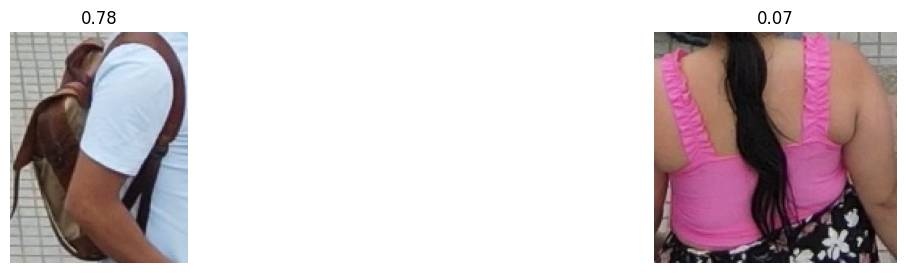

In [16]:
clase_objetivo = "backpack"
d = det[det.data["class_name"] == clase_objetivo]
d = d[np.argsort(-d.confidence)][:8]   # las 8 más confiables

recortes = [sv.crop_image(image, xyxy) for xyxy in d.xyxy]
if recortes:
    sv.plot_images_grid(recortes, grid_size=(1, len(recortes)),
                        titles=[f"{c:.2f}" for c in d.confidence], size=(16, 3))
else:
    print(f"No hay detecciones de '{clase_objetivo}'")

# Parte II · Video

Un video es una **secuencia de imágenes** (frames). Podemos aplicar el detector a cada frame, pero eso solo responde *"¿qué hay en este instante?"*.

Para preguntas como *"¿cuántas personas distintas pasaron?"* necesitamos **seguimiento** (*tracking*): asignar un **ID persistente** a cada objeto entre frames.

```
frame t   ──► YOLO-World ──► detecciones──┐
                                          ├──► ByteTrack ──► detecciones + tracker_id ──► conteo / trayectorias / mapa de calor
frame t-1 (estado del tracker) ───────────┘
```

**ByteTrack** asocia detecciones entre frames usando un filtro de Kalman (predice dónde estará cada objeto) y el IoU entre cajas. Su truco es aprovechar también las detecciones de **baja confianza** para no perder objetos parcialmente ocultos.

VideoInfo(width=2688, height=1512, fps=29.97002997002997, total_frames=199)
Duración: 6.6 s


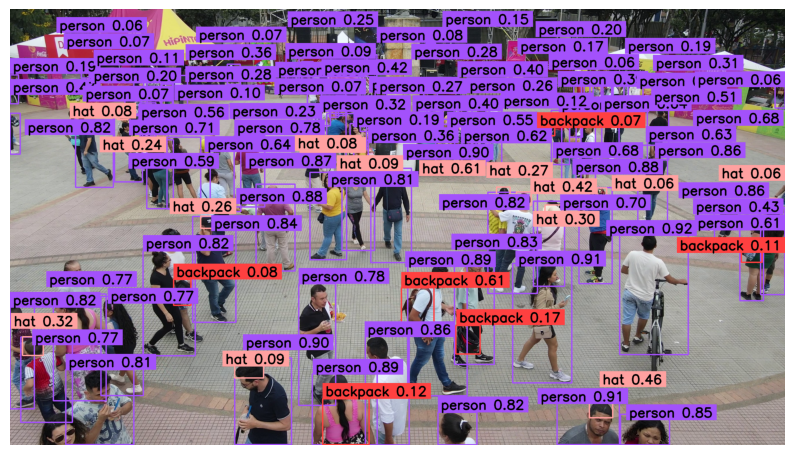

,clase,n,conf_media,conf_max
0,person,83,0.510,0.915
1,hat,15,0.229,0.608
2,backpack,6,0.195,0.611


In [17]:
video_info = sv.VideoInfo.from_video_path(SOURCE_VIDEO_PATH)
print(video_info)
print(f"Duración: {video_info.total_frames / video_info.fps:.1f} s")

# Buena práctica: probar parámetros en UN frame antes de procesar todo el video
primer_frame = next(sv.get_video_frames_generator(SOURCE_VIDEO_PATH))
det = detectar(primer_frame, ["person", "backpack", "hat"], confianza=0.05)
sv.plot_image(anotar(primer_frame, det), (10, 10))
resumen(det)

### Función general para procesar video

Una sola función con interruptores para activar cada técnica. Parámetros didácticos:

- `stride`: procesa 1 de cada *n* frames (más rápido; útil en clase).
- `max_frames`: limita la duración procesada.
- `trayectorias`, `linea`, `mapa_calor`: activan cada visualización.

In [18]:
def procesar_video(origen, destino, clases, confianza=0.05, nms=0.5,
                   stride=1, max_frames=None,
                   trayectorias=True, linea=None, mapa_calor=False,
                   csv_path=None, campaña="demo"):
    """
    linea: None o ((x1, y1), (x2, y2)) en coordenadas relativas 0-1.
    Devuelve un diccionario con estadísticas del procesamiento.
    """
    info = sv.VideoInfo.from_video_path(origen)
    fps_salida = info.fps / stride
    info_salida = sv.VideoInfo(width=info.width, height=info.height,
                               fps=fps_salida, total_frames=info.total_frames // stride)
    W, H = info.width, info.height

    # --- Tracker: umbrales bajos porque las confianzas de YOLO-World suelen ser bajas
    tracker = ByteTrackTracker(frame_rate=fps_salida,
                               track_activation_threshold=max(confianza, 0.15),
                               high_conf_det_threshold=0.3,
                               lost_track_buffer=int(fps_salida))

    # --- Anotadores (color por ID de seguimiento)
    grosor = sv.calculate_optimal_line_thickness((W, H))
    escala = sv.calculate_optimal_text_scale((W, H))
    box   = sv.BoxAnnotator(thickness=grosor, color_lookup=sv.ColorLookup.TRACK)
    label = sv.LabelAnnotator(text_scale=escala, text_thickness=grosor,
                              color_lookup=sv.ColorLookup.TRACK, smart_position=True)
    trace = sv.TraceAnnotator(thickness=grosor, trace_length=int(2 * fps_salida),
                              position=sv.Position.BOTTOM_CENTER,
                              color_lookup=sv.ColorLookup.TRACK)
    heat  = sv.HeatMapAnnotator(position=sv.Position.BOTTOM_CENTER,
                                opacity=0.5, radius=max(20, W // 40))

    line_zone = line_ann = None
    if linea is not None:
        (x1, y1), (x2, y2) = linea
        line_zone = sv.LineZone(start=sv.Point(int(x1 * W), int(y1 * H)),
                                end=sv.Point(int(x2 * W), int(y2 * H)),
                                triggering_anchors=[sv.Position.BOTTOM_CENTER])  # "los pies"
        line_ann = sv.LineZoneAnnotator(thickness=grosor, text_scale=escala,
                                        text_thickness=grosor,
                                        custom_in_text="entran", custom_out_text="salen")

    ids_por_clase = {c: set() for c in clases}
    filas_tiempo = []
    t0 = time.time()

    fin = None if max_frames is None else min(max_frames * stride, info.total_frames)
    frames = sv.get_video_frames_generator(origen, stride=stride, end=fin)
    total = info.total_frames // stride if max_frames is None else min(max_frames, info.total_frames // stride)

    csv_sink = sv.CSVSink(csv_path) if csv_path else None
    if csv_sink: csv_sink.open()

    with sv.VideoSink(destino, info_salida) as sink:
        for i, frame in enumerate(tqdm(frames, total=total, desc="Procesando")):
            det = detectar(frame, clases, confianza=confianza, nms=nms)
            det = tracker.update(det, frame)
            det = det[det.tracker_id != -1]          # solo tracks ya confirmados

            for cid_nombre, tid in zip(det.data.get("class_name", []), det.tracker_id):
                ids_por_clase.setdefault(cid_nombre, set()).add(int(tid))
            filas_tiempo.append({"frame": i, "t_seg": i / fps_salida,
                                 **{c: int(np.sum(det.data.get("class_name", np.array([])) == c)) for c in clases}})

            out = frame.copy()
            if mapa_calor:
                out = heat.annotate(out, det)
            if trayectorias:
                out = trace.annotate(out, det)
            out = box.annotate(out, det)
            etiquetas = [f"#{t} {n} {c:.2f}" for t, n, c in
                         zip(det.tracker_id, det.data.get("class_name", []), det.confidence)]
            out = label.annotate(out, det, labels=etiquetas)
            if line_zone is not None:
                line_zone.trigger(det)
                out = line_ann.annotate(out, line_counter=line_zone)

            sink.write_frame(out)
            if csv_sink:
                csv_sink.append(det, custom_data={"frame": i, "campaña": campaña})

    if csv_sink: csv_sink.close()
    dt = time.time() - t0
    stats = {
        "frames_procesados": len(filas_tiempo),
        "fps_procesamiento": round(len(filas_tiempo) / dt, 2),
        "objetos_unicos": {c: len(s) for c, s in ids_por_clase.items()},
        "serie_temporal": pd.DataFrame(filas_tiempo),
    }
    if line_zone is not None:
        stats["linea"] = {"entran": line_zone.in_count, "salen": line_zone.out_count}
    return stats

## Ejemplo 7 · Seguimiento con ID y trayectorias

Cada objeto conserva su número `#ID` y dibujamos la **estela** de sus últimos 2 segundos.

> 💬 **Compara:** "personas en un frame" (detección) vs "personas **distintas** en todo el video" (seguimiento). ¿Por qué el segundo número no es la suma del primero en todos los frames?

In [ ]:
CLASES_VIDEO = ["person", "backpack", "hat"]

stats = procesar_video(SOURCE_VIDEO_PATH, f"{OUT_DIR}/video_tracking.mp4",
                       CLASES_VIDEO, confianza=0.05,
                       csv_path=f"{OUT_DIR}/detecciones_video.csv",
                       campaña="sombreros y mochilas")

print("FPS de procesamiento:", stats["fps_procesamiento"])
print("Objetos únicos (por ID):", stats["objetos_unicos"])
mostrar_video(f"{OUT_DIR}/video_tracking.mp4")

## Ejemplo 8 · Conteo de visitantes con una línea virtual

Caso de uso real (**conteo de visitantes**): trazamos una línea y contamos cuántas personas la **cruzan** en cada sentido.
Usamos como punto de disparo la parte inferior central de la caja (**los pies**), que es más estable que las esquinas.

Las coordenadas de la línea son **relativas** (0 a 1), así la misma configuración sirve para videos de cualquier resolución.

In [ ]:
LINEA = ((0.0, 0.55), (1.0, 0.55))    # línea horizontal al 55 % de la altura

stats_linea = procesar_video(SOURCE_VIDEO_PATH, f"{OUT_DIR}/video_linea.mp4",
                             ["person"], confianza=0.1,
                             trayectorias=True, linea=LINEA)

print("Cruces de la línea:", stats_linea["linea"])
print("Personas únicas vistas:", stats_linea["objetos_unicos"]["person"])
mostrar_video(f"{OUT_DIR}/video_linea.mp4")

## Ejemplo 9 · Mapa de calor: ¿por dónde camina la gente?

El `HeatMapAnnotator` **acumula** la posición de los pies de cada persona a lo largo del tiempo. Las zonas rojas son las más transitadas: útil para analizar flujo en pasillos, tiendas o museos.

In [ ]:
stats_calor = procesar_video(SOURCE_VIDEO_PATH, f"{OUT_DIR}/video_calor.mp4",
                             ["person"], confianza=0.1,
                             trayectorias=False, mapa_calor=True)
mostrar_video(f"{OUT_DIR}/video_calor.mp4")

## Ejemplo 10 · Análisis temporal

¿Cómo cambia la cantidad de objetos a lo largo del video? Usamos la serie temporal que devolvió `procesar_video()` y la suavizamos con una media móvil de 1 segundo.

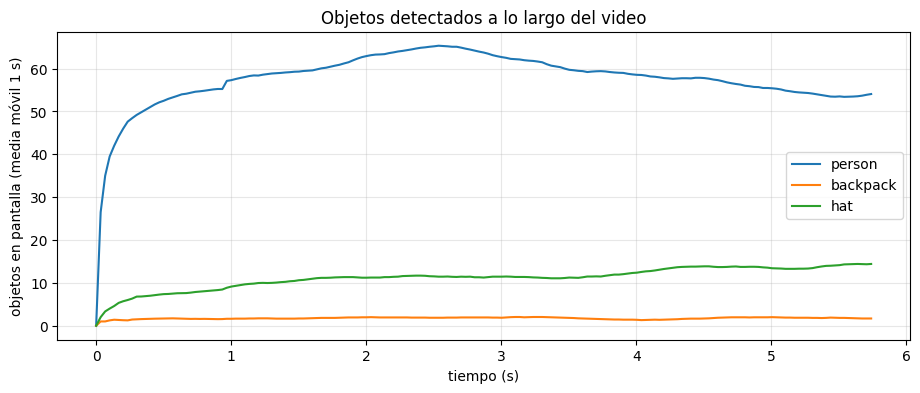

,person,backpack,hat
count,173.00,173.00,173.00
mean,58.39,1.76,11.84
std,6.11,0.64,2.48
min,0.00,0.00,0.00
25%,55.00,1.00,10.00
50%,59.00,2.00,12.00
75%,61.00,2.00,13.00
max,68.00,3.00,17.00


In [22]:
serie = stats["serie_temporal"].set_index("t_seg")[CLASES_VIDEO]
ventana = max(1, int(video_info.fps))

ax = serie.rolling(ventana, min_periods=1).mean().plot(figsize=(11, 4))
ax.set_xlabel("tiempo (s)"); ax.set_ylabel("objetos en pantalla (media móvil 1 s)")
ax.set_title("Objetos detectados a lo largo del video"); ax.grid(alpha=.3)
plt.show()

serie.describe().round(2)

In [23]:
# El CSV del video incluye frame, tracker_id y clase: podemos medir cuánto tiempo permanece cada ID
dfv = pd.read_csv(f"{OUT_DIR}/detecciones_video.csv")
permanencia = (dfv.groupby(["tracker_id", "class_name"])["frame"]
                  .agg(primer_frame="min", ultimo_frame="max", frames="count")
                  .reset_index())
permanencia["segundos_en_escena"] = (permanencia.frames / video_info.fps).round(2)
permanencia.sort_values("segundos_en_escena", ascending=False).head(10)

,tracker_id,class_name,primer_frame,ultimo_frame,frames,segundos_en_escena
0,0,person,1,172,172,5.74
17,15,person,1,172,172,5.74
42,38,hat,1,172,172,5.74
52,46,hat,1,172,172,5.74
43,39,person,1,172,172,5.74
39,36,backpack,1,172,172,5.74
37,34,person,1,172,172,5.74
32,29,person,1,172,172,5.74
31,28,person,1,172,172,5.74
58,51,person,1,172,172,5.74


## Ejemplo 11 · Tu propio video (rápido con `stride`)

Para videos largos o de alta resolución usa `stride=2` o `3` (procesa 1 de cada *n* frames) y `max_frames` para probar rápido.
Si subiste un archivo en la sección 0, cambia la ruta aquí. Por ejemplo, el video vertical `14996095_1080_1920_30fps.mp4` del notebook original.

In [24]:
MI_VIDEO = f"{DATA_DIR}/14996095_1080_1920_30fps.mp4"   # ← cambia por tu archivo
MIS_CLASES = ["person", "dog", "bicycle", "umbrella"]    # ← ¡escribe lo que quieras buscar!

if os.path.exists(MI_VIDEO):
    stats_mio = procesar_video(MI_VIDEO, f"{OUT_DIR}/mi_video.mp4", MIS_CLASES,
                               confianza=0.05, stride=2, max_frames=300,
                               linea=((0.0, 0.6), (1.0, 0.6)))
    print(stats_mio["objetos_unicos"], stats_mio.get("linea"))
    mostrar_video(f"{OUT_DIR}/mi_video.mp4", ancho=360)
else:
    print("No se encontró el archivo. Súbelo en la sección 0 o cambia MI_VIDEO.")

No se encontró el archivo. Súbelo en la sección 0 o cambia MI_VIDEO.


# Parte III · Experimento: ¿el tamaño del vocabulario afecta la velocidad?

En la introducción dijimos que YOLO-World codifica el texto **una sola vez**. Comprobémoslo: medimos el tiempo de inferencia con 1, 5, 20 y 50 clases.

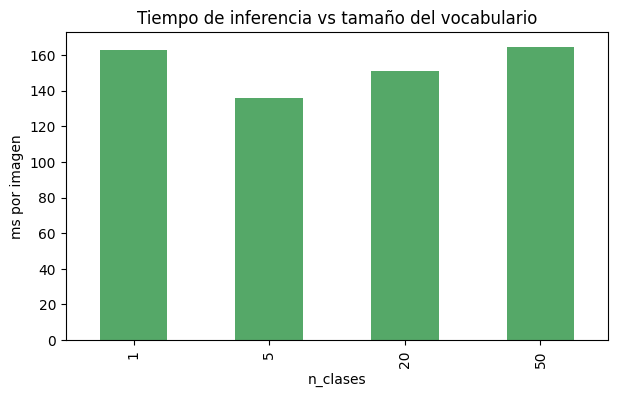

,n_clases,ms_por_imagen
0,1,163.0
1,5,135.9
2,20,150.9
3,50,164.7


In [25]:
vocab_grande = ["person", "backpack", "hat", "handbag", "sunglasses", "shoe", "jacket", "bag",
                "umbrella", "bicycle", "car", "dog", "bench", "tree", "window", "door", "sign",
                "bottle", "cup", "phone", "watch", "scarf", "glasses", "helmet", "suitcase",
                "chair", "table", "lamp", "flag", "banner", "camera", "stroller", "cap",
                "skirt", "dress", "shirt", "pants", "boots", "sneakers", "belt", "wallet",
                "laptop", "book", "poster", "trash can", "plant", "pole", "railing", "stairs", "column"]

tiempos = []
for n in [1, 5, 20, 50]:
    clases = vocab_grande[:n]
    detectar(image, clases)                      # calentamiento + set_classes
    t0 = time.time()
    for _ in range(10):
        detectar(image, clases)
    tiempos.append({"n_clases": n, "ms_por_imagen": (time.time() - t0) / 10 * 1000})

df_t = pd.DataFrame(tiempos).round(1)
ax = df_t.plot.bar(x="n_clases", y="ms_por_imagen", legend=False, figsize=(7, 4), color="#55A868")
ax.set_ylabel("ms por imagen"); ax.set_title("Tiempo de inferencia vs tamaño del vocabulario")
plt.show()
df_t

# Resumen

| Concepto | Lo que vimos |
|---|---|
| Vocabulario abierto | Detectar clases nuevas escribiendo su nombre (`set_classes`) |
| Umbral de confianza | Compromiso precisión/recall; en YOLO-World suele ser bajo y dependiente de la clase |
| Prompts | La redacción cambia el resultado; frases largas tienden a marcar el objeto principal |
| NMS | Umbral IoU muy bajo borra objetos cercanos; el modo agnóstico une clases sinónimas |
| Tracking | ByteTrack asigna IDs persistentes → conteo de objetos **únicos** |
| Analítica | Línea virtual, mapa de calor, series temporales, permanencia |


## Referencias
- Cheng, T. et al. (2024). *YOLO-World: Real-Time Open-Vocabulary Object Detection*. CVPR 2024. arXiv:2401.17270
- Zhang, Y. et al. (2022). *ByteTrack: Multi-Object Tracking by Associating Every Detection Box*. ECCV 2022.
- Documentación de `supervision`: https://supervision.roboflow.com
- Documentación de `trackers`: https://github.com/roboflow/trackers